# Fine-tuning and targeted freezing

* How to perform targeted freezing
* Various ways of measuring the impact of freezing on loss, token usage, and computation time
* Difficulty of fine-tuning comes from the myriad of choices and the time investment of testing

# Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig
import requests

import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')

In [2]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Models

In [3]:
!pip install -U bitsandbytes>=0.46.1

In [4]:
tokenizer = AutoTokenizer.from_pretrained("EleutherAI/gpt-neo-2.7B")
tokenizer.pad_token_id = tokenizer.encode(' ')[0]

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

model_freeze = AutoModelForCausalLM.from_pretrained('EleutherAI/gpt-neo-125m').to(device)
model_train  = AutoModelForCausalLM.from_pretrained('EleutherAI/gpt-neo-125m').to(device)

config.json:   0%|          | 0.00/1.46k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/798k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/90.0 [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/160 [00:00<?, ?it/s]

[transformers] GPTNeoForCausalLM LOAD REPORT from: EleutherAI/gpt-neo-125m
Key                                                   | Status     |  | 
------------------------------------------------------+------------+--+-
transformer.h.{0, 2, 4, 6, 8, 10}.attn.attention.bias | UNEXPECTED |  | 
transformer.h.{0...11}.attn.attention.masked_bias     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


generation_config.json:   0%|          | 0.00/119 [00:00<?, ?B/s]

Loading weights:   0%|          | 0/160 [00:00<?, ?it/s]

[transformers] GPTNeoForCausalLM LOAD REPORT from: EleutherAI/gpt-neo-125m
Key                                                   | Status     |  | 
------------------------------------------------------+------------+--+-
transformer.h.{0, 2, 4, 6, 8, 10}.attn.attention.bias | UNEXPECTED |  | 
transformer.h.{0...11}.attn.attention.masked_bias     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


# Moby Dick Download

In [5]:
text = requests.get('https://www.gutenberg.org/cache/epub/2701/pg2701.txt').text
mb_tokens = tokenizer.encode(text, return_tensors='pt')[0]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (354290 > 2048). Running this sequence through the model will result in indexing errors


In [6]:
len(mb_tokens)

354290

# Token Frequency

In [7]:
# create a filtered token vector initialized to zeros
mb_tokens_filt = np.full(len(mb_tokens), -1, dtype=int)

# copy over the token only if it has >2 characters
for t in range(len(mb_tokens)):
  if len(tokenizer.decode(mb_tokens[t]))>2:
    mb_tokens_filt[t] = mb_tokens[t]

uniq, counts = np.unique(mb_tokens_filt, return_counts=True)
freq_idx = np.argsort(counts)[::-1]
top100 = uniq[freq_idx[1:101]]

for t in top100:
  print(f'Token "{tokenizer.decode([t]):^10}" ({t:^6}) appears {np.sum(mb_tokens_filt==t):^6} times and is "{tokenizer.decode([t]):^10}"')

Token "    the   " ( 262  ) appears 13157  times and is "    the   "
Token "    of    " ( 286  ) appears  6402  times and is "    of    "
Token "    and   " ( 290  ) appears  5708  times and is "    and   "
Token "    to    " ( 284  ) appears  4437  times and is "    to    "
Token "    in    " ( 287  ) appears  3853  times and is "    in    "
Token "   that   " ( 326  ) appears  2749  times and is "   that   "
Token "    his   " ( 465  ) appears  2351  times and is "    his   "
Token "    it    " ( 340  ) appears  2108  times and is "    it    "
Token "    is    " ( 318  ) appears  1657  times and is "    is    "
Token "   with   " ( 351  ) appears  1600  times and is "   with   "
Token "    he    " ( 339  ) appears  1596  times and is "    he    "
Token "    was   " ( 373  ) appears  1552  times and is "    was   "
Token "    as    " ( 355  ) appears  1541  times and is "    as    "
Token "    all   " ( 477  ) appears  1391  times and is "    all   "
Token "    for   " ( 329  ) appear

# Quantify Common Token Usage Pretraining

In [8]:
num_reps = 10  # number of random repetitions
num_toks = 100  # output length

# initialize
token_usage = np.zeros((2,2))  # [ pre/post]

# random starting tokens
rand_starts = torch.randint(tokenizer.vocab_size, (num_reps,1)).to(device)

# FREEZE: generate and store tokens
out_freeze = model_freeze.generate(rand_starts,
                               min_length  = num_toks+1,
                               max_length  = num_toks+1,
                               do_sample= True,
                               pad_token_id = tokenizer.pad_token_id).cpu()
gen_tokens_freeze = out_freeze[:,1:].reshape(-1)

# TRAIN: generate and store tokens
out_train = model_train.generate(rand_starts,
                               min_length  = num_toks+1,
                               max_length  = num_toks+1,
                               do_sample= True,
                               pad_token_id = tokenizer.pad_token_id).cpu()
gen_tokens_train = out_train[:,1:].reshape(-1)

# calculate the percentage
token_usage[0,0] = np.mean(100*np.isin(gen_tokens_freeze, top100))
token_usage[0,1] = np.mean(100*np.isin(gen_tokens_train, top100))  # EDGAR model, Alice tokens

In [9]:
token_usage

array([[28.3, 21.6],
       [ 0. ,  0. ]])

# Freeze Weights

We want to train only the attention weights (QKV only) in layers 6+.

In [10]:
for name, params in model_freeze.named_parameters():
  print(f'Trainable: {params.requires_grad}\n{name}')
  split_str = name.split('.')
  print(split_str,'\n')

Trainable: True
transformer.wte.weight
['transformer', 'wte', 'weight'] 

Trainable: True
transformer.wpe.weight
['transformer', 'wpe', 'weight'] 

Trainable: True
transformer.h.0.ln_1.weight
['transformer', 'h', '0', 'ln_1', 'weight'] 

Trainable: True
transformer.h.0.ln_1.bias
['transformer', 'h', '0', 'ln_1', 'bias'] 

Trainable: True
transformer.h.0.attn.attention.k_proj.weight
['transformer', 'h', '0', 'attn', 'attention', 'k_proj', 'weight'] 

Trainable: True
transformer.h.0.attn.attention.v_proj.weight
['transformer', 'h', '0', 'attn', 'attention', 'v_proj', 'weight'] 

Trainable: True
transformer.h.0.attn.attention.q_proj.weight
['transformer', 'h', '0', 'attn', 'attention', 'q_proj', 'weight'] 

Trainable: True
transformer.h.0.attn.attention.out_proj.weight
['transformer', 'h', '0', 'attn', 'attention', 'out_proj', 'weight'] 

Trainable: True
transformer.h.0.attn.attention.out_proj.bias
['transformer', 'h', '0', 'attn', 'attention', 'out_proj', 'bias'] 

Trainable: True
transf

In [11]:
for name, params in model_freeze.named_parameters():

    if not name.startswith('transformer.h.'):
        params.requires_grad = False
        continue

    layer = int(name.split('.')[2])

    if not (layer >= 6 and 'attn' in name and any(x in name for x in ('k_proj', 'q_proj', 'v_proj'))):
        params.requires_grad = False

In [12]:
for name, params in model_freeze.named_parameters():
  print(f'Trainable: {params.requires_grad:2} | {name}')

Trainable:  0 | transformer.wte.weight
Trainable:  0 | transformer.wpe.weight
Trainable:  0 | transformer.h.0.ln_1.weight
Trainable:  0 | transformer.h.0.ln_1.bias
Trainable:  0 | transformer.h.0.attn.attention.k_proj.weight
Trainable:  0 | transformer.h.0.attn.attention.v_proj.weight
Trainable:  0 | transformer.h.0.attn.attention.q_proj.weight
Trainable:  0 | transformer.h.0.attn.attention.out_proj.weight
Trainable:  0 | transformer.h.0.attn.attention.out_proj.bias
Trainable:  0 | transformer.h.0.ln_2.weight
Trainable:  0 | transformer.h.0.ln_2.bias
Trainable:  0 | transformer.h.0.mlp.c_fc.weight
Trainable:  0 | transformer.h.0.mlp.c_fc.bias
Trainable:  0 | transformer.h.0.mlp.c_proj.weight
Trainable:  0 | transformer.h.0.mlp.c_proj.bias
Trainable:  0 | transformer.h.1.ln_1.weight
Trainable:  0 | transformer.h.1.ln_1.bias
Trainable:  0 | transformer.h.1.attn.attention.k_proj.weight
Trainable:  0 | transformer.h.1.attn.attention.v_proj.weight
Trainable:  0 | transformer.h.1.attn.attent

And for model_train

In [13]:
for name, params in model_train.named_parameters():
  print(f'Trainable: {params.requires_grad:2} | {name}')

Trainable:  1 | transformer.wte.weight
Trainable:  1 | transformer.wpe.weight
Trainable:  1 | transformer.h.0.ln_1.weight
Trainable:  1 | transformer.h.0.ln_1.bias
Trainable:  1 | transformer.h.0.attn.attention.k_proj.weight
Trainable:  1 | transformer.h.0.attn.attention.v_proj.weight
Trainable:  1 | transformer.h.0.attn.attention.q_proj.weight
Trainable:  1 | transformer.h.0.attn.attention.out_proj.weight
Trainable:  1 | transformer.h.0.attn.attention.out_proj.bias
Trainable:  1 | transformer.h.0.ln_2.weight
Trainable:  1 | transformer.h.0.ln_2.bias
Trainable:  1 | transformer.h.0.mlp.c_fc.weight
Trainable:  1 | transformer.h.0.mlp.c_fc.bias
Trainable:  1 | transformer.h.0.mlp.c_proj.weight
Trainable:  1 | transformer.h.0.mlp.c_proj.bias
Trainable:  1 | transformer.h.1.ln_1.weight
Trainable:  1 | transformer.h.1.ln_1.bias
Trainable:  1 | transformer.h.1.attn.attention.k_proj.weight
Trainable:  1 | transformer.h.1.attn.attention.v_proj.weight
Trainable:  1 | transformer.h.1.attn.attent

# Fine Tune

We're going to collect norm of current and previous h_6_attn_k weights. We're going also to measure and collect time of forward and backward pass for each iteration.

In [14]:
# hyperparameters
seq_len    = 256 # max sequence length
batch_size = 16

# use GPU
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

In [15]:
optimizer_train  = torch.optim.AdamW(model_train.parameters(),  lr=0.0005)
optimizer_freeze = torch.optim.AdamW(model_freeze.parameters(), lr=0.0005)

In [17]:
print(model_freeze is model_train)

print(
    model_freeze.transformer.h[6].attn.attention.k_proj.weight.data_ptr()
    == model_train.transformer.h[6].attn.attention.k_proj.weight.data_ptr()
)

print(sum(p.numel() for g in optimizer_freeze.param_groups for p in g['params']))
print(sum(p.numel() for p in model_freeze.parameters() if p.requires_grad))

False
False
125198592
10616832


In [19]:
import time

num_samples = 474
token_probs = np.zeros((num_samples, 3))

# initialize losses
train_loss_freeze = []
train_loss_train = []

# initialize norms collect
h_6_attn_k_norms_freeze = torch.zeros(num_samples)
h_6_attn_k_norms_train = torch.zeros(num_samples)

prev_h_6_attn_k_freeze = model_freeze.transformer.h[6].attn.attention.k_proj.weight.detach().clone()
prev_h_6_attn_k_train = model_train.transformer.h[6].attn.attention.k_proj.weight.detach().clone()

# initialize time collect
times_freeze = torch.zeros(num_samples, 2)
times_train = torch.zeros(num_samples, 2)

for sampli in range(num_samples):

    # get a batch of data
    ix = torch.randint(len(mb_tokens)-seq_len, size=(batch_size,))
    X = mb_tokens[ix[:, None] + torch.arange(seq_len)].to(device)

    # ==================== FREEZE MODEL ====================

    model_freeze.zero_grad()

    if device.type == 'cuda':
      torch.cuda.synchronize()
    start = time.time()

    outputs_freeze = model_freeze(X, labels=X)
    loss_freeze = outputs_freeze.loss

    if device.type == 'cuda':
      torch.cuda.synchronize()
    time_forward_freeze = time.time() - start

    if device.type == 'cuda':
      torch.cuda.synchronize()
    start = time.time()

    loss_freeze.backward()

    if device.type == 'cuda':
      torch.cuda.synchronize()
    time_backward_freeze = time.time() - start

    optimizer_freeze.step()

    train_loss_freeze.append(loss_freeze.item())

    curr_h_6_attn_k_freeze = model_freeze.transformer.h[6].attn.attention.k_proj.weight.detach().clone()

    h_6_attn_k_norm_freeze = torch.norm(curr_h_6_attn_k_freeze - prev_h_6_attn_k_freeze).item()
    h_6_attn_k_norms_freeze[sampli] = h_6_attn_k_norm_freeze

    prev_h_6_attn_k_freeze = curr_h_6_attn_k_freeze

    times_freeze[sampli, 0] = time_forward_freeze
    times_freeze[sampli, 1] = time_backward_freeze


    # ==================== TRAIN MODEL ====================

    model_train.zero_grad()

    if device.type == 'cuda':
      torch.cuda.synchronize()
    start = time.time()

    outputs_train = model_train(X, labels=X)
    loss_train = outputs_train.loss

    if device.type == 'cuda':
      torch.cuda.synchronize()
    time_forward_train = time.time() - start

    if device.type == 'cuda':
      torch.cuda.synchronize()
    start = time.time()

    loss_train.backward()

    if device.type == 'cuda':
      torch.cuda.synchronize()
    time_backward_train = time.time() - start

    optimizer_train.step()

    train_loss_train.append(loss_train.item())

    curr_h_6_attn_k_train = model_train.transformer.h[6].attn.attention.k_proj.weight.detach().clone()

    h_6_attn_k_norm_train = torch.norm(curr_h_6_attn_k_train - prev_h_6_attn_k_train).item()
    h_6_attn_k_norms_train[sampli] = h_6_attn_k_norm_train

    prev_h_6_attn_k_train = curr_h_6_attn_k_train

    times_train[sampli, 0] = time_forward_train
    times_train[sampli, 1] = time_backward_train


    # logs
    if sampli % 20 == 0:
        print(
            f'Sample {sampli:4}/{num_samples} | '
            f'freeze loss: {train_loss_freeze[-1]:.4f} | '
            f'train loss: {train_loss_train[-1]:.4f} | '
            f'freeze F/B: {time_forward_freeze:.4f}/{time_backward_freeze:.4f}s | '
            f'train F/B: {time_forward_train:.4f}/{time_backward_train:.4f}s'
        )

Sample    0/474 | freeze loss: 4.9943 | train loss: 7.3804 | freeze F/B: 0.4330/0.3027s | train F/B: 0.4093/0.8005s
Sample   20/474 | freeze loss: 3.5286 | train loss: 3.6471 | freeze F/B: 0.4182/0.3282s | train F/B: 0.4383/0.8371s
Sample   40/474 | freeze loss: 3.6393 | train loss: 3.4003 | freeze F/B: 0.4054/0.3152s | train F/B: 0.4284/0.8261s
Sample   60/474 | freeze loss: 3.6118 | train loss: 3.2269 | freeze F/B: 0.4219/0.3257s | train F/B: 0.4351/0.8492s
Sample   80/474 | freeze loss: 3.5778 | train loss: 3.1281 | freeze F/B: 0.4077/0.3147s | train F/B: 0.4288/0.8305s
Sample  100/474 | freeze loss: 3.5040 | train loss: 2.9694 | freeze F/B: 0.4164/0.3216s | train F/B: 0.4366/0.8522s
Sample  120/474 | freeze loss: 3.4328 | train loss: 2.7217 | freeze F/B: 0.4081/0.3190s | train F/B: 0.4287/0.8243s
Sample  140/474 | freeze loss: 3.4056 | train loss: 2.6017 | freeze F/B: 0.4104/0.3194s | train F/B: 0.4337/0.8390s
Sample  160/474 | freeze loss: 3.3634 | train loss: 2.2430 | freeze F/B:

# Visualization

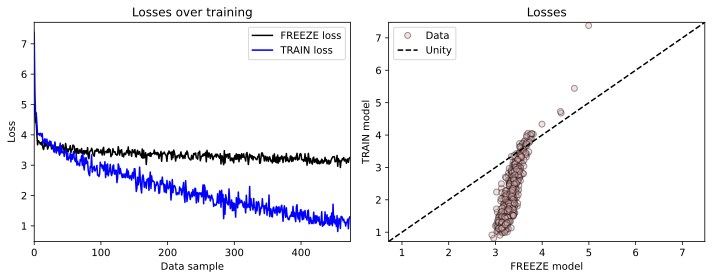

In [20]:
losses = np.column_stack((train_loss_freeze, train_loss_train))

_, axs = plt.subplots(1, 2, figsize=(10, 4))

axs[0].plot(losses[:, 0], 'k', markersize=8, label='FREEZE loss')
axs[0].plot(losses[:, 1], 'b', markersize=8, label='TRAIN loss')
axs[0].legend()
axs[0].set(xlabel='Data sample', ylabel='Loss', xlim=[0, num_samples], title='Losses over training')

axs[1].plot(losses[:, 0], losses[:, 1], 'ko', markerfacecolor=[.9, .7, .7], alpha=.4, label='Data')

xylim = [np.min(losses)-.1, np.max(losses)+.1]

axs[1].plot(xylim, xylim, 'k--', zorder=3, label='Unity')
axs[1].set(xlabel='FREEZE model', ylabel='TRAIN model', title='Losses', xlim=xylim, ylim=xylim)
axs[1].legend()

plt.tight_layout()
plt.show()

In [22]:
out_freeze = model_freeze.generate(rand_starts, min_length=num_toks+1, max_length=num_toks+1, do_sample=True, pad_token_id=tokenizer.pad_token_id)
out_train = model_train.generate(rand_starts, min_length=num_toks+1, max_length=num_toks+1, do_sample=True, pad_token_id=tokenizer.pad_token_id)

gen_tokens_freeze_after = out_freeze[:, 1:].cpu().reshape(-1)
gen_tokens_train_after = out_train[:, 1:].cpu().reshape(-1)

token_usage[1, 0] = np.mean(100 * np.isin(gen_tokens_freeze_after, top100))
token_usage[1, 1] = np.mean(100 * np.isin(gen_tokens_train_after, top100))

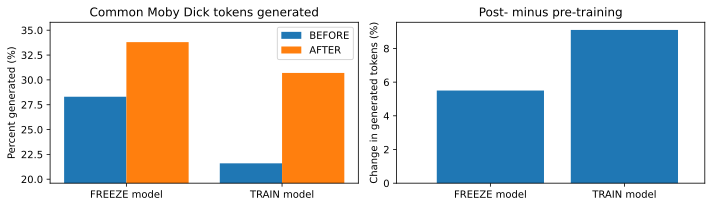

In [23]:
_, axs = plt.subplots(1, 2, figsize=(10, 3))

# show the pre-train token usage
axs[0].bar([.8, 1.8], token_usage[0, :], width=.4, label='BEFORE')
axs[0].bar([1.2, 2.2], token_usage[1, :], width=.4, label='AFTER')

axs[0].set(
    ylim=[min(token_usage.flatten()) - 2, max(token_usage.flatten()) + 2],
    xticks=[1, 2],
    xticklabels=['FREEZE model', 'TRAIN model'],
    ylabel='Percent generated (%)',
    title='Common Moby Dick tokens generated'
)

axs[0].legend()

# post minus pre
axs[1].bar([1, 2], np.diff(token_usage, axis=0)[0])

axs[1].set(
    xticks=[1, 2],
    xlim=[.3, 2.6],
    xticklabels=['FREEZE model', 'TRAIN model'],
    ylabel='Change in generated tokens (%)',
    title='Post- minus pre-training'
)

plt.tight_layout()
plt.show()

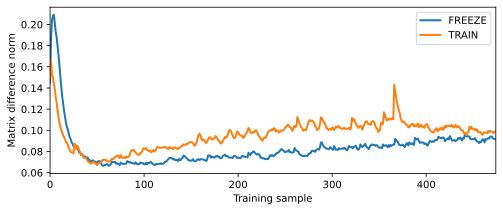

In [24]:
# weight-change norm
plt.figure(figsize=(8, 3))

plt.plot(h_6_attn_k_norms_freeze, linewidth=2, label='FREEZE')
plt.plot(h_6_attn_k_norms_train, linewidth=2, label='TRAIN')

plt.legend()
plt.gca().set(
    xlim=[0, num_samples],
    xlabel='Training sample',
    ylabel='Matrix difference norm'
)

plt.show()

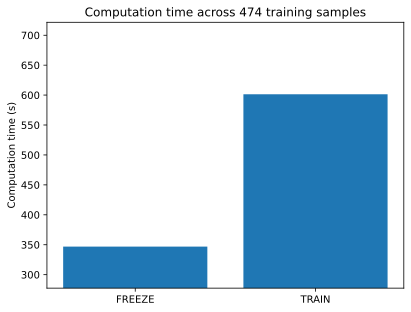

In [25]:
# computation time
time_freeze = times_freeze.sum().item()
time_train = times_train.sum().item()

plt.bar([1, 2], [time_freeze, time_train])

plt.gca().set(
    xticks=[1, 2],
    xticklabels=['FREEZE', 'TRAIN'],
    ylabel='Computation time (s)',
    ylim=[min(time_freeze, time_train) * .8, max(time_freeze, time_train) * 1.2],
    title=f'Computation time across {num_samples} training samples'
)

plt.show()

# Conclusion

* Precision freezing isn't so difficult to implement; knowing which weights to freeze and why is challenging and uncertain
* Freezing has many trade-offs
* Hopefully, increased research on mechanistic interpretability will help guide targeted fine-tuning